### Data Preparation & EDA

##### 1. Setup: Import Library dan Konfigurasi

In [1]:
import sys, os
sys.path.append("..")   # agar config.py di folder induk bisa diimpor

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from config import RANDOM_STATE, TEST_SIZE, DATA_PATH, OUTPUT_DIR

os.makedirs(OUTPUT_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Python  :", sys.version.split()[0])
print("pandas  :", pd.__version__)
print("numpy   :", np.__version__)
print("sklearn :", sklearn.__version__)

Python  : 3.12.10
pandas  : 3.1.1
numpy   : 2.5.5
sklearn : 1.9.1


##### 2. Load Dataset dan Verifikasi
**Deskripsi singkat dataset**
- Setiap baris adalah satu sesi kunjungan ke website e-commerce.
- 17 fitur (aktivitas halaman, bounce/exit rate, page value, bulan, tipe pengunjung, dll.) dan 1 target.
- Target: `Revenue` (True = sesi berakhir dengan pembelian, False = tidak).

In [2]:
df = pd.read_csv(DATA_PATH)
print("Ukuran data:", df.shape)

assert df.shape == (12330, 18), "Ukuran data tidak sesuai, cek file CSV!"
assert "Revenue" in df.columns, "Kolom Revenue tidak ditemukan!"
print("Verifikasi lolos")
df.head()

Ukuran data: (12330, 18)
Verifikasi lolos


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.000,0,0.000,2,64.000,0.000,0.100,0.000,0.000,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.000,0,0.000,2,2.667,0.050,0.140,0.000,0.000,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.000,0,0.000,10,627.500,0.020,0.050,0.000,0.000,Feb,3,3,1,4,Returning_Visitor,True,False


##### 3. Pemeriksaan Struktur dan Tipe Data

Memastikan setiap kolom bertipe sesuai isinya: fitur numerik berupa `int`/`float`, `Month` dan `VisitorType` berupa teks, serta `Weekend` dan `Revenue` berupa boolean.

In [3]:
df.info()
print()
print(df.dtypes.value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

##### 4. Pemeriksaan Missing Value

Missing value dapat menyebabkan error atau bias pada KNN dan Random Forest, sehingga harus diperiksa sebelum modeling.

In [4]:
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value")
print("\nTotal missing:", missing.sum())

Tidak ada missing value

Total missing: 0


##### 5. Statistik Deskriptif

Statistik deskriptif digunakan untuk melihat rentang nilai, rata-rata, dan sebaran fitur numerik. Bagian ini juga menunjukkan perbedaan skala antar fitur.

In [ ]:
num_cols = ["Administrative", "Administrative_Duration", "Informational",
            "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
            "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

df[num_cols].describe().T[["min", "mean", "50%", "max"]]

,min,mean,50%,max
Administrative,0.000,2.315,1.000,27.000
Administrative_Duration,0.000,80.819,7.500,"3,398.750"
Informational,0.000,0.504,0.000,24.000
Informational_Duration,0.000,34.472,0.000,"2,549.375"
ProductRelated,0.000,31.731,18.000,705.000
ProductRelated_Duration,0.000,"1,194.746",598.937,"63,973.522"
BounceRates,0.000,0.022,0.003,0.200
ExitRates,0.000,0.043,0.025,0.200
PageValues,0.000,5.889,0.000,361.764
SpecialDay,0.000,0.061,0.000,1.000


##### 6. Pemeriksaan Nilai Nol dan Kolom Kategori Berkode

Banyak fitur aktivitas bernilai 0 karena pengunjung memang tidak membuka jenis halaman tersebut (bukan data hilang). Kolom `OperatingSystems`, `Browser`, `Region`, `TrafficType` berupa kode kategori yang disimpan sebagai angka.

In [6]:
print("Jumlah nilai 0 per fitur numerik:")
print((df[num_cols] == 0).sum())

print("\nJumlah kategori unik pada kolom berkode:")
for col in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    print(f"{col:18s}: {df[col].nunique()} kategori")

print("\nDistribusi SpecialDay:")
print(df["SpecialDay"].value_counts().sort_index())

Jumlah nilai 0 per fitur numerik:
Administrative              5768
Administrative_Duration     5903
Informational               9699
Informational_Duration      9925
ProductRelated                38
ProductRelated_Duration      755
BounceRates                 5518
ExitRates                     76
PageValues                  9600
SpecialDay                 11079
dtype: int64

Jumlah kategori unik pada kolom berkode:
OperatingSystems  : 8 kategori
Browser           : 13 kategori
Region            : 9 kategori
TrafficType       : 20 kategori

Distribusi SpecialDay:
SpecialDay
0.000    11079
0.200      178
0.400      243
0.600      351
0.800      325
1.000      154
Name: count, dtype: int64


##### 7. Deteksi Data Duplikat

In [7]:
n_dup = df.duplicated().sum()
print("Jumlah baris duplikat:", n_dup, f"({n_dup/len(df)*100:.2f}%)")

print("\nRevenue pada baris duplikat:")
print(df[df.duplicated()]["Revenue"].value_counts())

print("\nContoh baris duplikat:")
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

Jumlah baris duplikat: 125 (1.01%)

Revenue pada baris duplikat:
Revenue
False    125
Name: count, dtype: int64

Contoh baris duplikat:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
8247,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Dec,1,1,1,1,Returning_Visitor,True,False
10751,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Dec,1,1,1,1,Returning_Visitor,True,False
11658,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Dec,1,1,1,1,Returning_Visitor,True,False
8882,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Dec,1,1,1,2,New_Visitor,False,False
11934,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Dec,1,1,1,2,New_Visitor,False,False
11110,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Dec,1,1,1,3,Returning_Visitor,False,False


##### 8. Pemeriksaan Konsistensi Data

Pemeriksaan logika sederhana untuk menemukan nilai yang tidak konsisten.

In [8]:
dur_cols = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]
print("Nilai negatif pada durasi:", (df[dur_cols] < 0).sum().sum())

total_pages = df["Administrative"] + df["Informational"] + df["ProductRelated"]
print("Sesi dengan 0 halaman dibuka:", (total_pages == 0).sum())

print("BounceRates > ExitRates:", (df["BounceRates"] > df["ExitRates"]).sum())
print("Administrative > 0 tetapi durasi = 0:",
      ((df["Administrative"] > 0) & (df["Administrative_Duration"] == 0)).sum())

Nilai negatif pada durasi: 0
Sesi dengan 0 halaman dibuka: 6
BounceRates > ExitRates: 175
Administrative > 0 tetapi durasi = 0: 135


##### 9. Distribusi Target (Revenue)

Distribusi kelas target diperiksa untuk mengetahui apakah data seimbang. Hal ini menentukan metrik evaluasi yang layak dipakai.

         jumlah  persen
Revenue                
False     10422  84.530
True       1908  15.470

Rasio tidak-beli : beli = 5.46 : 1
Akurasi jika selalu menebak 'tidak beli': 84.53%


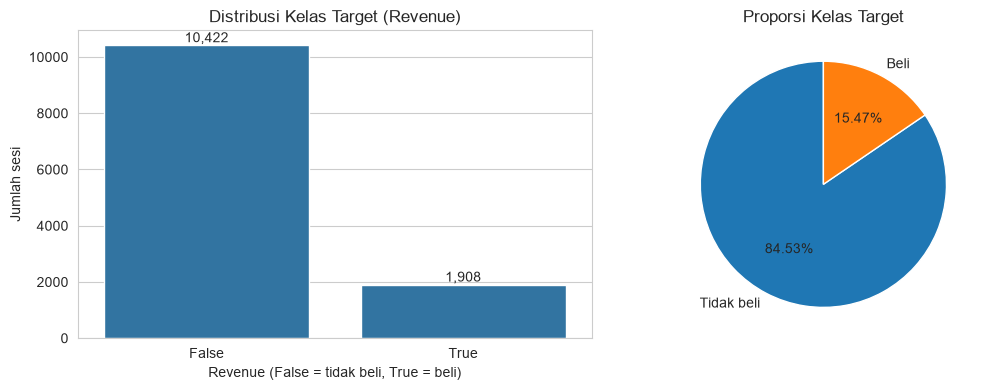

In [9]:
counts = df["Revenue"].value_counts()
pct = df["Revenue"].value_counts(normalize=True) * 100
print(pd.DataFrame({"jumlah": counts, "persen": pct.round(2)}))
print(f"\nRasio tidak-beli : beli = {counts[False] / counts[True]:.2f} : 1")
print(f"Akurasi jika selalu menebak 'tidak beli': {pct[False]:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(x="Revenue", data=df, ax=axes[0])
axes[0].set_title("Distribusi Kelas Target (Revenue)")
axes[0].set_xlabel("Revenue (False = tidak beli, True = beli)")
axes[0].set_ylabel("Jumlah sesi")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}",
                     (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

axes[1].pie(counts.sort_index(), labels=["Tidak beli", "Beli"],
            autopct="%1.2f%%", startangle=90)
axes[1].set_title("Proporsi Kelas Target")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/01_distribusi_target.png", dpi=150)
plt.show()

##### 10. Frekuensi Fitur Kategorikal

Melihat isi dan jumlah tiap kategori pada `Month`, `VisitorType`, dan `Weekend`.

In [10]:
for col in ["Month", "VisitorType", "Weekend"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(), "\n")

--- Month ---
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64 

--- VisitorType ---
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64 

--- Weekend ---
Weekend
False    9462
True     2868
Name: count, dtype: int64 



##### 11. Pembelian per Bulan

Selain jumlah sesi, dihitung **conversion rate** (persentase sesi yang berakhir dengan pembelian) per bulan. Jumlah sesi saja bisa menyesatkan karena bulan dengan sesi banyak belum tentu konversinya tinggi.

Revenue  False  True  total  conversion_%
Month                                    
Feb        181     3    184         1.630
Mar       1715   192   1907        10.070
May       2999   365   3364        10.850
June       259    29    288        10.070
Jul        366    66    432        15.280
Aug        357    76    433        17.550
Sep        362    86    448        19.200
Oct        434   115    549        20.950
Nov       2238   760   2998        25.350
Dec       1511   216   1727        12.510


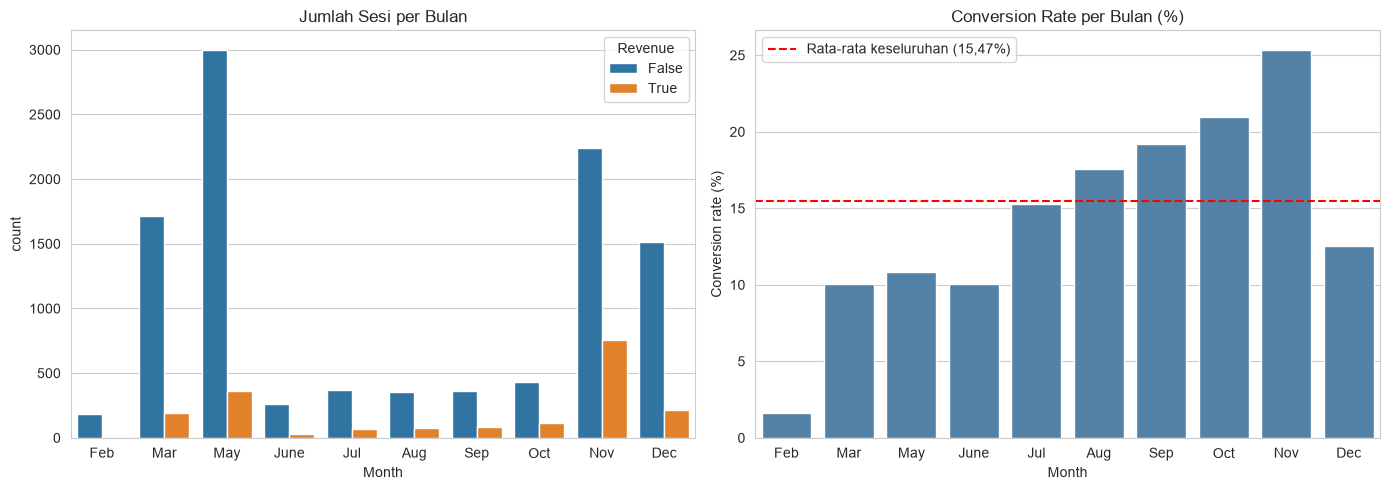

In [11]:
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

month_tab = pd.crosstab(df["Month"], df["Revenue"]).reindex(month_order)
month_tab["total"] = month_tab.sum(axis=1)
month_tab["conversion_%"] = (month_tab[True] / month_tab["total"] * 100).round(2)
print(month_tab)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="Month", hue="Revenue", data=df, order=month_order, ax=axes[0])
axes[0].set_title("Jumlah Sesi per Bulan")

sns.barplot(x=month_tab.index, y=month_tab["conversion_%"], ax=axes[1], color="steelblue")
axes[1].axhline(15.47, color="red", linestyle="--", label="Rata-rata keseluruhan (15,47%)")
axes[1].set_title("Conversion Rate per Bulan (%)")
axes[1].set_ylabel("Conversion rate (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/02_pembelian_per_bulan.png", dpi=150)
plt.show()

##### 12. Pembelian Berdasarkan Tipe Pengunjung dan Akhir Pekan

Membandingkan conversion rate antar kelompok `VisitorType` dan `Weekend`.

Revenue            False  True  total  conversion_%
VisitorType                                        
New_Visitor         1272   422   1694        24.910
Other                 69    16     85        18.820
Returning_Visitor   9081  1470  10551        13.930 

Revenue  False  True  total  conversion_%
Weekend                                  
True      2369   499   2868        17.400
False     8053  1409   9462        14.890


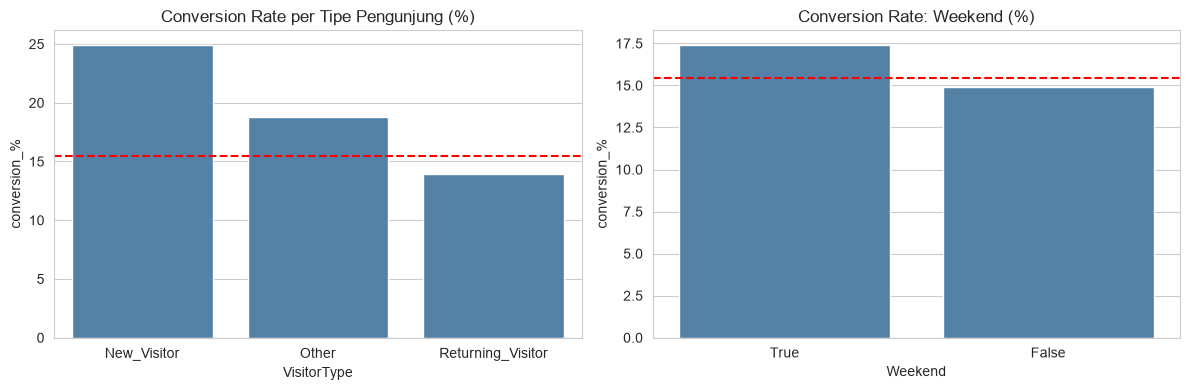

In [12]:
def conversion_table(col):
    t = pd.crosstab(df[col], df["Revenue"])
    t["total"] = t.sum(axis=1)
    t["conversion_%"] = (t[True] / t["total"] * 100).round(2)
    return t.sort_values("conversion_%", ascending=False)

vt = conversion_table("VisitorType")
wk = conversion_table("Weekend")
print(vt, "\n")
print(wk)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=vt.index, y=vt["conversion_%"], ax=axes[0], color="steelblue")
axes[0].axhline(15.47, color="red", linestyle="--")
axes[0].set_title("Conversion Rate per Tipe Pengunjung (%)")

sns.barplot(x=wk.index.astype(str), y=wk["conversion_%"], ax=axes[1], color="steelblue")
axes[1].axhline(15.47, color="red", linestyle="--")
axes[1].set_title("Conversion Rate: Weekend (%)")
axes[1].set_xlabel("Weekend")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/03_visitor_weekend.png", dpi=150)
plt.show()

##### 13. Distribusi Fitur Numerik

Melihat bentuk sebaran tiap fitur numerik dengan histogram dan skewness. Skewness positif besar berarti sebagian besar nilai kecil dengan sedikit nilai sangat besar. Hasilnya menjadi dasar pembahasan outlier dan skala fitur.

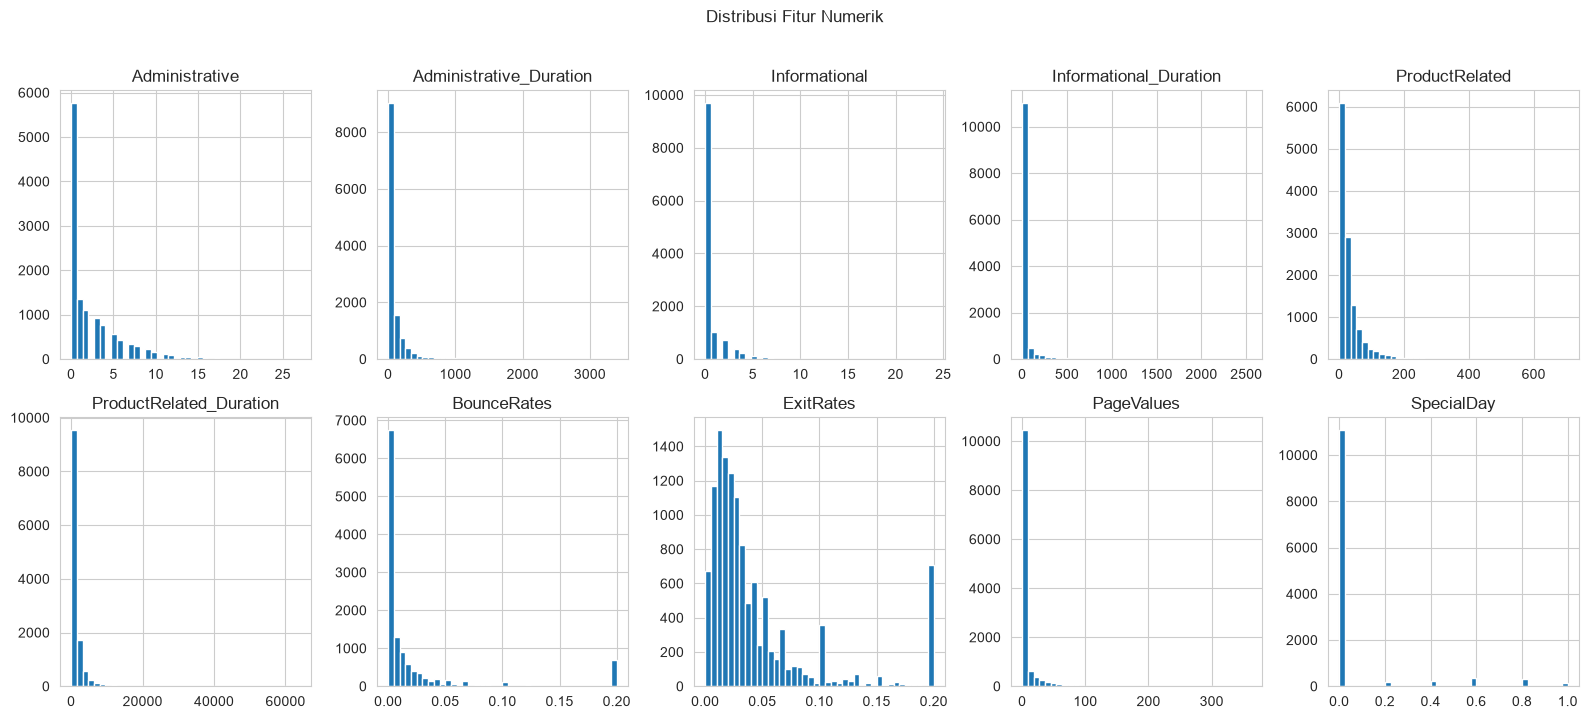

Skewness tiap fitur (urut dari terbesar):
Informational_Duration    7.580
ProductRelated_Duration   7.260
PageValues                6.380
Administrative_Duration   5.620
ProductRelated            4.340
Informational             4.040
SpecialDay                3.300
BounceRates               2.950
ExitRates                 2.150
Administrative            1.960
dtype: float64


In [13]:
df[num_cols].hist(bins=40, figsize=(16, 7), layout=(2, 5))
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/04_distribusi_numerik.png", dpi=150, bbox_inches="tight")
plt.show()

print("Skewness tiap fitur (urut dari terbesar):")
print(df[num_cols].skew().sort_values(ascending=False).round(2))

##### 14. Korelasi Antar Fitur dan dengan Target

Menghitung korelasi Pearson antar fitur numerik, dengan `Revenue` diubah menjadi 0/1 hanya untuk perhitungan ini. Tujuannya mengetahui fitur yang paling berhubungan dengan pembelian dan pasangan fitur yang saling tumpang tindih (relevan untuk Soal 1).

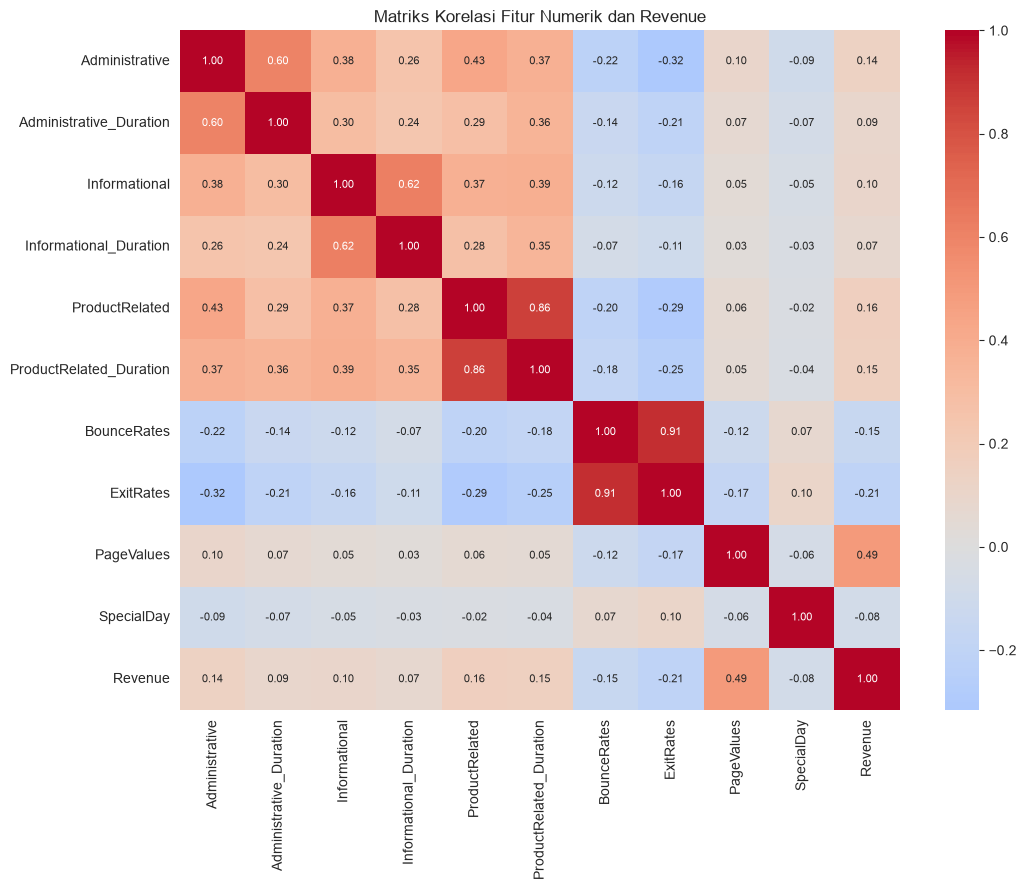

Korelasi dengan Revenue:
PageValues                 0.493
ProductRelated             0.159
ProductRelated_Duration    0.152
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
Informational_Duration     0.070
SpecialDay                -0.082
BounceRates               -0.151
ExitRates                 -0.207
Name: Revenue, dtype: float64

Pasangan fitur dengan korelasi tertinggi:
BounceRates     ExitRates                 0.913
ProductRelated  ProductRelated_Duration   0.861
Informational   Informational_Duration    0.619
Administrative  Administrative_Duration   0.602
                ProductRelated            0.431
Informational   ProductRelated_Duration   0.388
dtype: float64


In [14]:
d = df[num_cols].copy()
d["Revenue"] = df["Revenue"].astype(int)
corr = d.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 8})
plt.title("Matriks Korelasi Fitur Numerik dan Revenue")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/05_korelasi.png", dpi=150)
plt.show()

print("Korelasi dengan Revenue:")
print(corr["Revenue"].drop("Revenue").sort_values(ascending=False).round(3))

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
upper = upper.drop(labels=[i for i in upper.index if "Revenue" in i])
print("\nPasangan fitur dengan korelasi tertinggi:")
print(upper.reindex(upper.abs().sort_values(ascending=False).index).head(6).round(3))

##### 15. Perbandingan Pembeli vs Non-Pembeli

Membandingkan rata-rata dan median fitur antara sesi yang berakhir dengan pembelian dan yang tidak, ditambah boxplot lima fitur utama. Bagian ini menjadi bukti utama untuk Soal 1: aktivitas pengunjung berbeda antar kelas.

RATA-RATA per kelas Revenue:
Revenue                     False     True 
Administrative              2.118     3.394
Administrative_Duration    73.740   119.483
Informational               0.452     0.786
Informational_Duration     30.236    57.611
ProductRelated             28.715    48.210
ProductRelated_Duration 1,069.988 1,876.210
BounceRates                 0.025     0.005
ExitRates                   0.047     0.020
PageValues                  1.976    27.265
SpecialDay                  0.068     0.023

MEDIAN per kelas Revenue:
Revenue                   False     True 
Administrative            0.000     2.000
Administrative_Duration   0.000    52.367
Informational             0.000     0.000
Informational_Duration    0.000     0.000
ProductRelated           16.000    29.000
ProductRelated_Duration 510.190 1,109.906
BounceRates               0.004     0.000
ExitRates                 0.029     0.016
PageValues                0.000    16.758
SpecialDay                0.000     0.00

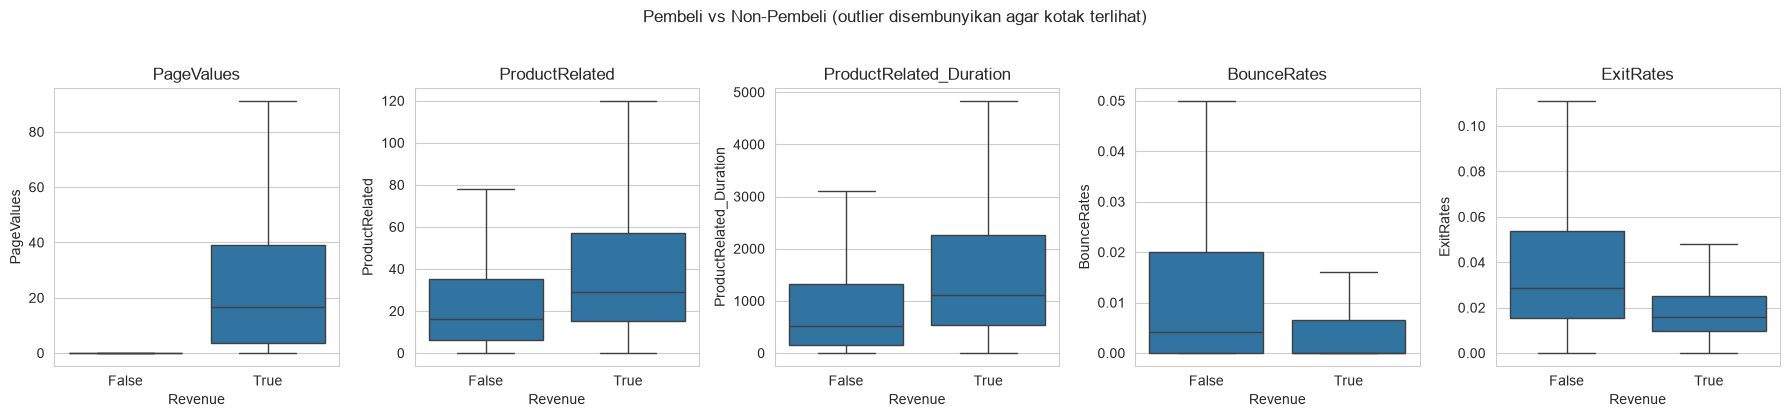

In [15]:
print("RATA-RATA per kelas Revenue:")
print(df.groupby("Revenue")[num_cols].mean().T.round(3))

print("\nMEDIAN per kelas Revenue:")
print(df.groupby("Revenue")[num_cols].median().T.round(3))

print("\nProporsi sesi dengan PageValues > 0:")
print(df.groupby("Revenue")["PageValues"].apply(lambda s: (s > 0).mean()).round(3))

key_cols = ["PageValues", "ProductRelated", "ProductRelated_Duration",
            "BounceRates", "ExitRates"]
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, key_cols):
    sns.boxplot(x="Revenue", y=col, data=df, ax=ax, showfliers=False)
    ax.set_title(col)
plt.suptitle("Pembeli vs Non-Pembeli (outlier disembunyikan agar kotak terlihat)", y=1.03)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/06_pembeli_vs_nonpembeli.png", dpi=150, bbox_inches="tight")
plt.show()

##### 16. Pemeriksaan Outlier

Mendeteksi nilai ekstrem dengan aturan IQR (di bawah Q1 - 1,5 x IQR atau di atas Q3 + 1,5 x IQR), lalu memeriksa perilaku pembelian pada sesi outlier untuk memutuskan apakah perlu dibuang.

In [16]:
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append([col, round(lo, 2), round(hi, 2), n, round(n / len(df) * 100, 2)])

outlier_df = pd.DataFrame(rows, columns=["fitur", "batas_bawah", "batas_atas",
                                         "jumlah_outlier", "persen"])
print(outlier_df.to_string(index=False))

q1, q3 = df["PageValues"].quantile([0.25, 0.75])
hi_pv = q3 + 1.5 * (q3 - q1)
out_pv = df[df["PageValues"] > hi_pv]
print(f"\nSesi 'outlier' PageValues: {len(out_pv)}")
print(f"Persentase yang membeli: {out_pv['Revenue'].mean() * 100:.2f}% "
      f"(rata-rata keseluruhan 15,47%)")

                  fitur  batas_bawah  batas_atas  jumlah_outlier  persen
         Administrative       -6.000      10.000             404   3.280
Administrative_Duration     -139.880     233.140            1172   9.510
          Informational        0.000       0.000            2631  21.340
 Informational_Duration        0.000       0.000            2405  19.510
         ProductRelated      -39.500      84.500             987   8.000
ProductRelated_Duration   -1,735.890   3,384.190             961   7.790
            BounceRates       -0.030       0.040            1551  12.580
              ExitRates       -0.040       0.100            1099   8.910
             PageValues        0.000       0.000            2730  22.140
             SpecialDay        0.000       0.000            1251  10.150

Sesi 'outlier' PageValues: 2730
Persentase yang membeli: 56.34% (rata-rata keseluruhan 15,47%)


##### 17. Perbedaan Skala Antar Fitur

Membandingkan nilai minimum, maksimum, dan simpangan baku tiap fitur untuk menunjukkan bahwa skala antar fitur sangat berbeda. Ini menjadi dasar kebutuhan scaling pada KNN.

                          min        max       std
Administrative          0.000     27.000     3.322
Administrative_Duration 0.000  3,398.750   176.779
Informational           0.000     24.000     1.270
Informational_Duration  0.000  2,549.375   140.749
ProductRelated          0.000    705.000    44.476
ProductRelated_Duration 0.000 63,973.522 1,913.669
BounceRates             0.000      0.200     0.048
ExitRates               0.000      0.200     0.049
PageValues              0.000    361.764    18.568
SpecialDay              0.000      1.000     0.199

Std terbesar : ProductRelated_Duration = 1,913.7
Std terkecil : BounceRates = 0.048
Rasio        : sekitar 39,868 kali


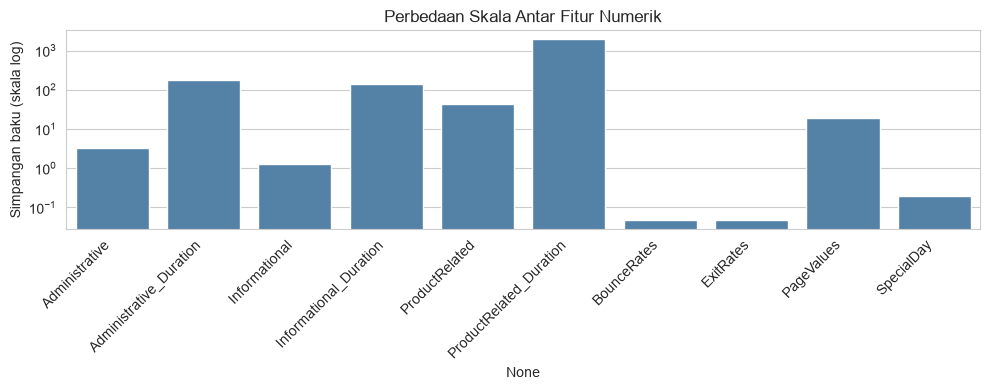

In [17]:
scale_df = df[num_cols].agg(["min", "max", "std"]).T.round(3)
print(scale_df)

ratio = scale_df["std"].max() / scale_df["std"].min()
print(f"\nStd terbesar : {scale_df['std'].idxmax()} = {scale_df['std'].max():,.1f}")
print(f"Std terkecil : {scale_df['std'].idxmin()} = {scale_df['std'].min():.3f}")
print(f"Rasio        : sekitar {ratio:,.0f} kali")

plt.figure(figsize=(10, 4))
sns.barplot(x=scale_df.index, y=scale_df["std"], color="steelblue")
plt.yscale("log")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Simpangan baku (skala log)")
plt.title("Perbedaan Skala Antar Fitur Numerik")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/07_skala_fitur.png", dpi=150)
plt.show()

##### 18. Ringkasan Temuan EDA

Rangkuman hasil pemeriksaan awal dan EDA.

- **Data:** 12.330 sesi, 18 kolom, tanpa missing value, 125 baris duplikat (1,01%, semuanya non-pembeli).
- **Target:** 84,53% tidak membeli dan 15,47% membeli (rasio 5,46 : 1). Model yang selalu menebak "tidak beli" sudah mencapai akurasi 84,53%.
- **Kategorikal:** conversion tertinggi November (25,35%), terendah Februari (1,63%); pengunjung baru 24,91% vs pengunjung lama 13,93%.
- **Numerik:** `PageValues` paling berkorelasi dengan `Revenue` (0,493); `ExitRates` (-0,207) dan `BounceRates` (-0,151) berkorelasi negatif. Semua fitur miring ke kanan.
- **Outlier dan skala:** outlier valid dan informatif (56,34% sesi outlier `PageValues` membeli); skala antar fitur berbeda sekitar 40.000 kali sehingga scaling diperlukan untuk KNN.

##### 19. Daftar Keputusan Preprocessing

Keputusan yang diambil berdasarkan hasil EDA.

| Aspek | Keputusan | Alasan |
|---|---|---|
| Missing value | Tidak ada tindakan | Tidak ada missing value (Cell 4) |
| Duplikat | Dipertahankan | Tidak ada ID sesi; sesi bounce identik bisa berasal dari pengunjung berbeda |
| Outlier | Dibiarkan | Nilai valid dan informatif; Random Forest tidak sensitif; scaling mengurangi pengaruh pada KNN |
| Encoding | One-hot `Month` dan `VisitorType`; `Weekend` dan `Revenue` menjadi 0/1 | Kategori tidak berurutan |
| Split | 80:20, stratified, `random_state=42` | Menjaga proporsi pembeli di train dan test |
| Scaling | `StandardScaler` pada 14 kolom numerik, fit hanya di train | Skala sangat berbeda; mencegah data leakage |

 Resampling tidak dilakukan pada model utama agar perbandingan KNN vs Random Forest murni.

##### 20. Encoding Fitur Kategorikal

Mengubah kolom teks dan boolean menjadi angka. `Month` dan `VisitorType` di-one-hot encoding (bukan label encoding, karena tidak punya urutan dan akan menipu KNN), sedangkan `Weekend` dan `Revenue` diubah menjadi 0/1. Kolom `OperatingSystems`, `Browser`, `Region`, dan `TrafficType` dibiarkan numerik.

In [18]:
df_enc = df.copy()
df_enc["Revenue"] = df_enc["Revenue"].astype(int)
df_enc["Weekend"] = df_enc["Weekend"].astype(int)
df_enc = pd.get_dummies(df_enc, columns=["Month", "VisitorType"], dtype=int)

print("Ukuran setelah encoding:", df_enc.shape)
print("Missing value          :", df_enc.isnull().sum().sum())
print("Tipe data              :", dict(df_enc.dtypes.value_counts()))
print("\nKolom baru hasil one-hot:")
print([c for c in df_enc.columns if c.startswith(("Month_", "VisitorType_"))])

Ukuran setelah encoding: (12330, 29)
Missing value          : 0
Tipe data              : {dtype('int64'): np.int64(22), dtype('float64'): np.int64(7)}

Kolom baru hasil one-hot:
['Month_Aug', 'Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_June', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_New_Visitor', 'VisitorType_Other', 'VisitorType_Returning_Visitor']


##### 21. Split Train dan Test (Stratified)

Membagi data 80% latih dan 20% uji dengan `stratify=y` dan `random_state=42`. Stratifikasi wajib pada data imbalanced agar proporsi pembeli di train dan test tetap sama (Soal 5).

In [19]:
X = df_enc.drop("Revenue", axis=1)
y = df_enc["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"Pembeli di train: {y_train.mean()*100:.2f}% ({y_train.sum()} dari {len(y_train)})")
print(f"Pembeli di test : {y_test.mean()*100:.2f}% ({y_test.sum()} dari {len(y_test)})")

# Pemeriksaan: baris test yang identik dengan baris train (efek mempertahankan duplikat)
n_overlap = X_test.reset_index().merge(
    X_train.drop_duplicates(), on=list(X.columns))["index"].nunique()
print(f"Baris test yang identik dengan baris train: {n_overlap}")

X_train: (9864, 28) | X_test: (2466, 28)
Pembeli di train: 15.47% (1526 dari 9864)
Pembeli di test : 15.49% (382 dari 2466)
Baris test yang identik dengan baris train: 29


##### 22. Scaling Fitur Numerik

Menyamakan skala 14 kolom numerik dengan `StandardScaler`. Scaler di-fit hanya pada data train, lalu dipakai untuk mentransformasi data test agar tidak terjadi data leakage. 14 kolom biner (`Weekend`, `Month_*`, `VisitorType_*`) tidak di-scale.

In [20]:
code_cols = ["OperatingSystems", "Browser", "Region", "TrafficType"]
scale_cols = num_cols + code_cols                       # num_cols dari Cell 5
binary_cols = [c for c in X.columns if c not in scale_cols]
print("Kolom di-scale:", len(scale_cols), "| kolom biner (tidak di-scale):", len(binary_cols))

scaler = StandardScaler()
X_train_scaled = X_train.copy().astype(float)
X_test_scaled = X_test.copy().astype(float)

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])   # fit HANYA di train
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])         # test hanya transform

print("\nTrain: rata-rata maks (absolut) :", X_train_scaled[scale_cols].mean().abs().max().round(3))
print("Train: std                      :", X_train_scaled[scale_cols].std(ddof=0).round(3).unique())
print("Test : rata-rata 5 fitur pertama:", X_test_scaled[scale_cols].mean().round(2).head(5).tolist())
print("Ukuran:", X_train_scaled.shape, X_test_scaled.shape,
      "| missing:", X_train_scaled.isnull().sum().sum())

Kolom di-scale: 14 | kolom biner (tidak di-scale): 14

Train: rata-rata maks (absolut) : 0.0
Train: std                      : [1.]
Test : rata-rata 5 fitur pertama: [-0.0, -0.01, -0.0, -0.0, 0.03]
Ukuran: (9864, 28) (2466, 28) | missing: 0


##### 23. Menyimpan Hasil Preprocessing

In [21]:
import joblib

PROCESSED_DIR = os.path.join(os.path.dirname(DATA_PATH), "processed")   # ../data/processed
os.makedirs(PROCESSED_DIR, exist_ok=True)

X_train.to_csv(f"{PROCESSED_DIR}/X_train.csv", index=False)
X_test.to_csv(f"{PROCESSED_DIR}/X_test.csv", index=False)
X_train_scaled.to_csv(f"{PROCESSED_DIR}/X_train_scaled.csv", index=False)
X_test_scaled.to_csv(f"{PROCESSED_DIR}/X_test_scaled.csv", index=False)
y_train.to_csv(f"{PROCESSED_DIR}/y_train.csv", index=False)
y_test.to_csv(f"{PROCESSED_DIR}/y_test.csv", index=False)
joblib.dump(scaler, f"{PROCESSED_DIR}/scaler.pkl")

catatan = f"""CATATAN PREPROCESSING 
random_state     : {RANDOM_STATE}
test_size        : {TEST_SIZE} (stratified)
buang duplikat   : tidak (125 duplikat dipertahankan)
encoding         : one-hot Month & VisitorType; Weekend & Revenue -> 0/1
scaler           : StandardScaler pada {len(scale_cols)} kolom numerik (fit di train)
ukuran train/test: {X_train.shape} / {X_test.shape}
pembeli train/test: {y_train.mean()*100:.2f}% / {y_test.mean()*100:.2f}%
target           : Revenue (1 = beli, 0 = tidak beli)
"""
with open(f"{PROCESSED_DIR}/CATATAN.txt", "w", encoding="utf-8") as f:
    f.write(catatan)

for name in sorted(os.listdir(PROCESSED_DIR)):
    size = os.path.getsize(os.path.join(PROCESSED_DIR, name)) / 1e6
    print(f"{name:22s} {size:6.2f} MB")

CATATAN.txt              0.00 MB
X_test.csv               0.22 MB
X_test_scaled.csv        0.83 MB
X_train.csv              0.89 MB
X_train_scaled.csv       3.34 MB
scaler.pkl               0.00 MB
y_test.csv               0.01 MB
y_train.csv              0.03 MB
